# Lab 3: Clustering with K-Means and K-Medoids

**Name:** Todd Simonson
**Course:** MSCS-634: Advanced Big Data and Data Mining
**Instructor:** Dr. Satish Penmatsa
**Assignment:** Lab 3: Comparing K-Means and K-Medoids Clustering on the Wine Dataset

## Step 1: Load and Prepare the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score, pairwise_distances

# k-medoids implementation (fasterpam algorithm), see the note in step 3
import kmedoids

pd.set_option('display.width', 160)
RANDOM_STATE = 42

In [2]:
wine = load_wine(as_frame=True)
X_raw = wine.data
y = wine.target
class_names = [str(n) for n in wine.target_names]

print('samples:', X_raw.shape[0], ' features:', X_raw.shape[1])
X_raw.head()

samples: 178  features: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Feature details

In [3]:
X_raw.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Observation:** The 13 chemical measurements are on very different scales. Proline has a standard deviation of 314.91 and a range of 278 to 1,680, while hue has a standard deviation of 0.23 and nonflavanoid phenols only 0.12. Distance-based clustering would be dominated by proline unless the features are put on a common scale, which is why standardization is the next step.

### Class distribution

         wines  percent
class_0     59     33.1
class_1     71     39.9
class_2     48     27.0


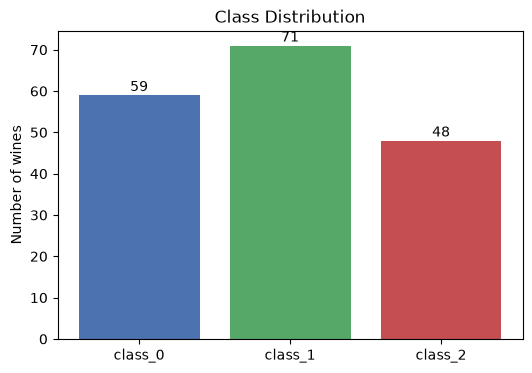

In [4]:
counts = y.value_counts().sort_index()
counts.index = class_names
print(pd.DataFrame({'wines': counts, 'percent': (counts / counts.sum() * 100).round(1)}))

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color=['#4C72B0', '#55A868', '#C44E52'])
for i, v in enumerate(counts.values):
    plt.text(i, v + 1, str(v), ha='center')
plt.ylabel('Number of wines')
plt.title('Class Distribution')
plt.show()

**Observation:** The three cultivars are reasonably balanced: 59 class_0 wines (33.1%), 71 class_1 (39.9%), and 48 class_2 (27.0%). Clustering does not use these labels. They are held back and used only afterward, to judge how closely each algorithm's clusters match the real cultivars through the Adjusted Rand Index.

### Standardization (z-score normalization)

Each feature is transformed to z = (x − mean) / standard deviation, giving every feature a mean of 0 and a standard deviation of 1. Both K-Means and K-Medoids assign wines by distance, so without this step proline would dominate every distance calculation and the other 12 measurements would barely count.

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

check = pd.DataFrame({'raw mean': X_raw.mean(), 'raw std': X_raw.std(ddof=0),
                      'scaled mean': X.mean(axis=0), 'scaled std': X.std(axis=0)}).round(3)
check.head(13)

,raw mean,raw std,scaled mean,scaled std
alcohol,13.001,0.810,0.0,1.0
malic_acid,2.336,1.114,0.0,1.0
ash,2.367,0.274,-0.0,1.0
alcalinity_of_ash,19.495,3.330,-0.0,1.0
magnesium,99.742,14.242,-0.0,1.0
total_phenols,2.295,0.624,-0.0,1.0
flavanoids,2.029,0.996,0.0,1.0
nonflavanoid_phenols,0.362,0.124,-0.0,1.0
proanthocyanins,1.591,0.571,-0.0,1.0
color_intensity,5.058,2.312,-0.0,1.0


## Step 2: K-Means Clustering (k = 3)

K-Means places 3 cluster centers, assigns each wine to its nearest center, moves each center to the mean of its assigned wines, and repeats until the assignments stop changing. Because the result depends on where the centers start, `n_init=10` runs the algorithm from 10 different starting points and keeps the best run.

In [6]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(X)

km_sil = silhouette_score(X, km_labels)
km_ari = adjusted_rand_score(y, km_labels)

print('cluster sizes:', np.bincount(km_labels))
print(f'silhouette score:    {km_sil:.4f}')
print(f'adjusted rand index: {km_ari:.4f}')

cluster sizes: [65 51 62]
silhouette score:    0.2849
adjusted rand index: 0.8975


In [7]:
# compare clusters with the true cultivars (labels were not used in training)
pd.crosstab(pd.Series(y.map(dict(enumerate(class_names))), name='true class'),
            pd.Series(km_labels, name='k-means cluster'))

k-means cluster,0,1,2
true class,,,
class_0,0,0,59
class_1,65,3,3
class_2,0,48,0


**Observation:** K-Means produced clusters of 65, 51, and 62 wines and recovered the true cultivars closely, with an Adjusted Rand Index of 0.8975 (1.0 would be a perfect match and 0 is what random assignment would produce). All 59 class_0 wines and all 48 class_2 wines landed together in their own clusters. The only mistakes involve class_1: 65 of its 71 wines formed their own cluster, 3 were grouped with class_0, and 3 with class_2. The silhouette score of 0.2849 means the clusters are real but not sharply separated. In 13 dimensions, the wine groups sit close together, especially around class_1.

## Step 3: K-Medoids Clustering (k = 3)

K-Medoids works like K-Means, but each cluster center must be an **actual wine** from the dataset (a medoid). The algorithm swaps medoids for other wines whenever the swap lowers the total distance from wines to their medoid. Because it minimizes total distance rather than squared distance, extreme points pull on the result less.

**Implementation note:** the commonly referenced `KMedoids` class in `scikit-learn-extra` cannot be installed on current Python versions. Its last release predates NumPy 2, and importing it fails on Python 3.12 and later. This notebook uses the maintained `kmedoids` package instead, which implements FasterPAM (Schubert & Rousseeuw, 2021). FasterPAM is an optimized version of the classic PAM (Partitioning Around Medoids) algorithm that finds the same kind of solution much faster. It is configured here with Euclidean distance so the results are directly comparable to K-Means.

In [8]:
kmed = kmedoids.KMedoids(n_clusters=3, metric='euclidean', method='fasterpam', random_state=RANDOM_STATE)
kmed.fit(X)
kmed_labels = kmed.labels_

kmed_sil = silhouette_score(X, kmed_labels)
kmed_ari = adjusted_rand_score(y, kmed_labels)

print('cluster sizes:', np.bincount(kmed_labels))
print(f'silhouette score:    {kmed_sil:.4f}')
print(f'adjusted rand index: {kmed_ari:.4f}')

cluster sizes: [55 74 49]
silhouette score:    0.2676
adjusted rand index: 0.7411


In [9]:
pd.crosstab(pd.Series(y.map(dict(enumerate(class_names))), name='true class'),
            pd.Series(kmed_labels, name='k-medoids cluster'))

k-medoids cluster,0,1,2
true class,,,
class_0,0,59,0
class_1,55,15,1
class_2,0,0,48


In [10]:
# the medoids are real wines, so their row numbers and true classes can be listed
medoids = pd.DataFrame({'wine index': kmed.medoid_indices_,
                        'true class': [class_names[y.iloc[i]] for i in kmed.medoid_indices_],
                        'cluster': range(3)})
pd.concat([medoids, X_raw.iloc[kmed.medoid_indices_][['alcohol', 'flavanoids', 'color_intensity', 'proline']]
           .reset_index(drop=True)], axis=1)

,wine index,true class,cluster,alcohol,flavanoids,color_intensity,proline
0,106,class_1,0,12.25,2.03,3.40,510.0
1,35,class_0,1,13.48,2.98,5.10,920.0
2,148,class_2,2,13.32,0.76,8.42,650.0


**Observation:** K-Medoids produced clusters of 55, 74, and 49 wines, with a silhouette score of 0.2676 and an ARI of 0.7411, both lower than K-Means. Class_0 and class_2 were again recovered completely, but the class_0 cluster grew to 74 wines because it absorbed 15 class_1 wines; 1 more class_1 wine joined the class_2 cluster. Each medoid is a real wine of the class it represents: wine 106 (class_1), wine 35 (class_0), and wine 148 (class_2). Their raw measurements match each cultivar's profile, for example the high proline of the class_0 medoid (920) and the low flavanoids (0.76) and high color intensity (8.42) of the class_2 medoid.

## Step 4: Visualize and Compare Results

### Projecting to two dimensions

The data has 13 dimensions, so it is projected onto its first two principal components (PCA) for plotting. The clustering itself was done in all 13 dimensions; PCA is used only for the picture. The K-Means centroids are projected the same way, and the medoids are plotted at the positions of their actual wines.

In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)
print('variance explained by pc1 and pc2:', pca.explained_variance_ratio_.round(3),
      f'(total {pca.explained_variance_ratio_.sum():.1%})')

centroids_2d = pca.transform(kmeans.cluster_centers_)
medoids_2d = X_2d[kmed.medoid_indices_]

variance explained by pc1 and pc2: [0.362 0.192] (total 55.4%)


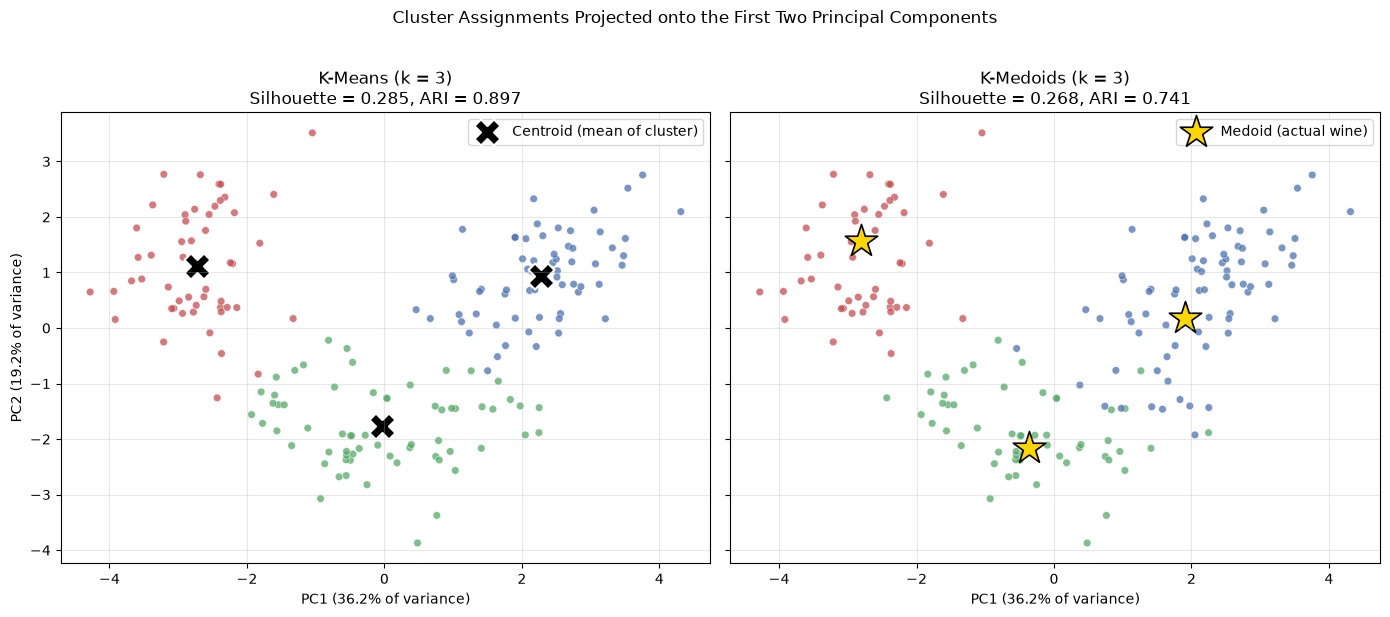

In [12]:
def color_by_class(labels):
    # renumber clusters to match the true class most of their members belong to, so colors line up across plots
    mapping = pd.crosstab(labels, y).idxmax(axis=1).to_dict()
    return np.array([mapping[l] for l in labels]), mapping

km_colors, km_map = color_by_class(km_labels)
kmed_colors, kmed_map = color_by_class(kmed_labels)
palette = np.array(['#4C72B0', '#55A868', '#C44E52'])

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=palette[km_colors], s=30, alpha=0.75, edgecolor='white', linewidth=0.4)
axes[0].scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='X', s=350, c='black', edgecolor='white',
                linewidth=1.5, label='Centroid (mean of cluster)')
axes[0].set_title(f'K-Means (k = 3)\nSilhouette = {km_sil:.3f}, ARI = {km_ari:.3f}')

axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=palette[kmed_colors], s=30, alpha=0.75, edgecolor='white', linewidth=0.4)
axes[1].scatter(medoids_2d[:, 0], medoids_2d[:, 1], marker='*', s=600, c='gold', edgecolor='black',
                linewidth=1.2, label='Medoid (actual wine)')
axes[1].set_title(f'K-Medoids (k = 3)\nSilhouette = {kmed_sil:.3f}, ARI = {kmed_ari:.3f}')

for ax in axes:
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)')
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3)
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)')
plt.suptitle('Cluster Assignments Projected onto the First Two Principal Components', y=1.02)
plt.tight_layout()
plt.show()

**Observation:** The first two principal components capture 55.4% of the variance and show the three groups as an arc: class_2 on the left, class_1 along the bottom, and class_0 on the right. The K-Means centroids (X) sit near the middle of each group. The medoids (stars) are close to the centroids for the class_2 and class_1 groups, but the class_0 medoid (wine 35) sits on the lower-left edge of the class_0 group, toward class_1, rather than in its center. Because each wine joins its nearest center, that offset pushes the class_0 cluster's boundary into the region where class_1 and class_0 meet. In the right plot, the class_0 cluster extends down into the space K-Means assigns to class_1.

### Reference: the true classes and each algorithm's mistakes

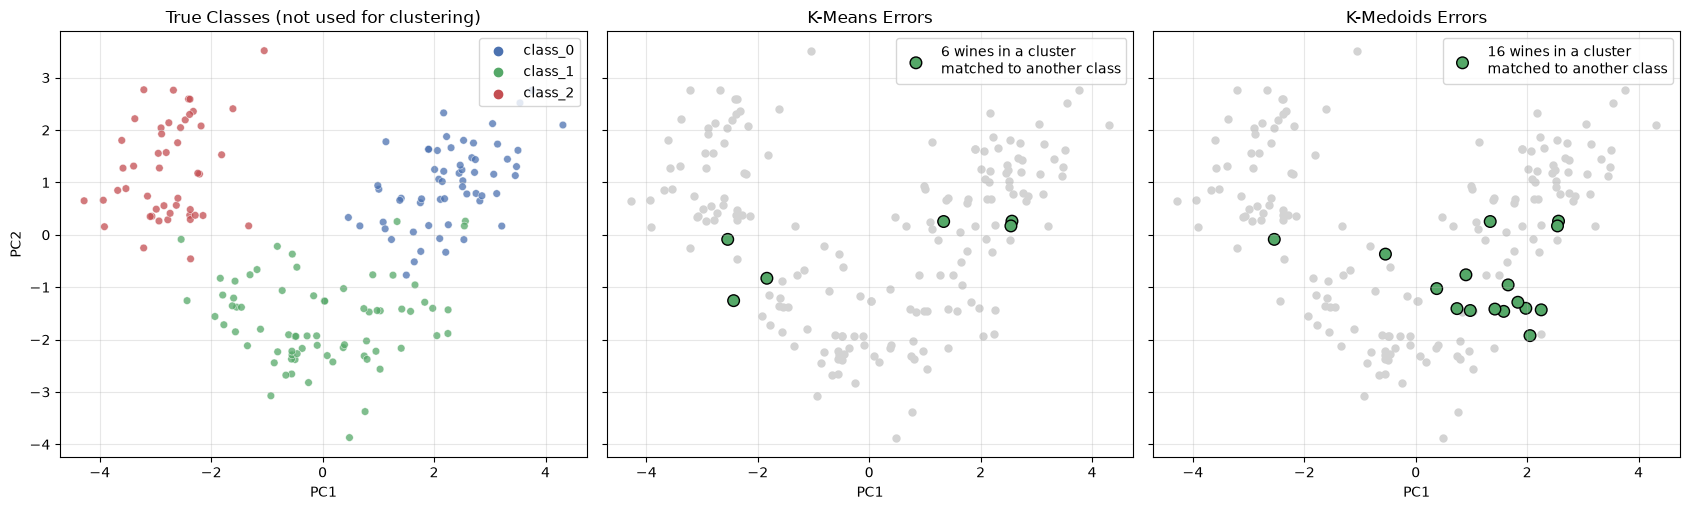

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)

axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=palette[y], s=30, alpha=0.75, edgecolor='white', linewidth=0.4)
for i, name in enumerate(class_names):
    axes[0].scatter([], [], c=palette[i], label=name)
axes[0].legend(loc='upper right')
axes[0].set_title('True Classes (not used for clustering)')

for ax, colors, title in [(axes[1], km_colors, 'K-Means Errors'), (axes[2], kmed_colors, 'K-Medoids Errors')]:
    wrong = colors != y.values
    ax.scatter(X_2d[~wrong, 0], X_2d[~wrong, 1], c='lightgray', s=25)
    ax.scatter(X_2d[wrong, 0], X_2d[wrong, 1], c=palette[y.values[wrong]], s=70, edgecolor='black',
               label=f'{wrong.sum()} wines in a cluster\nmatched to another class')
    ax.set_title(title)
    ax.legend(loc='upper right')

for ax in axes:
    ax.set_xlabel('PC1')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('PC2')
plt.tight_layout()
plt.show()

**Observation:** The error plots confirm where the two algorithms disagree. K-Means places 6 wines in clusters matched to a different class, all of them class_1 wines sitting near the edges of the class_0 or class_2 groups. K-Medoids places 16, and 15 of them form a tight band of class_1 wines between the class_1 and class_0 groups (around PC1 = 0.5 to 2.5, PC2 = -1.5 to 0). This is exactly the region the shifted class_0 medoid pulled into its cluster.

### Metric comparison

In [14]:
results = pd.DataFrame({
    'silhouette score': [km_sil, kmed_sil],
    'adjusted rand index': [km_ari, kmed_ari],
    'wines in a cluster matched to another class': [(km_colors != y.values).sum(), (kmed_colors != y.values).sum()],
}, index=['K-Means', 'K-Medoids']).round(4)
results

,silhouette score,adjusted rand index,wines in a cluster matched to another class
K-Means,0.2849,0.8975,6
K-Medoids,0.2676,0.7411,16


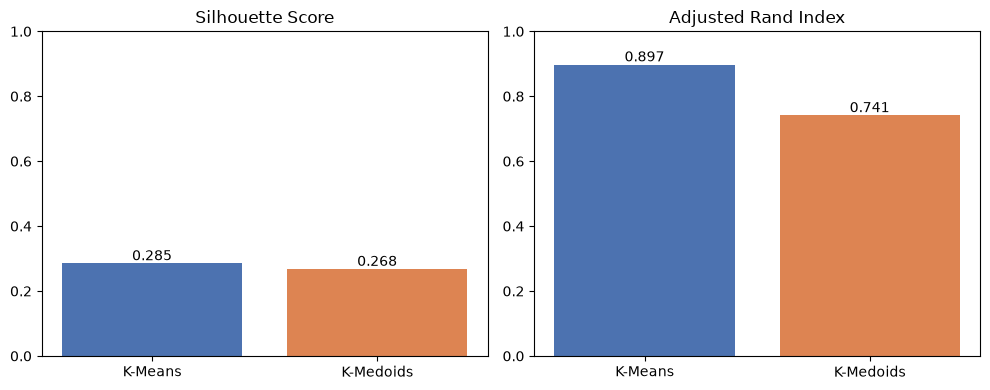

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ['silhouette score', 'adjusted rand index']):
    bars = ax.bar(results.index, results[col], color=['#4C72B0', '#DD8452'])
    for b, v in zip(bars, results[col]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.3f}', ha='center')
    ax.set_title(col.title())
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### Silhouette by cluster

The overall silhouette score is an average. Breaking it down by cluster shows which clusters are well separated and which ones overlap their neighbors. A sample silhouette near 1 means a wine sits well inside its cluster, near 0 means it is on a boundary, and below 0 means it is closer to another cluster than to its own.

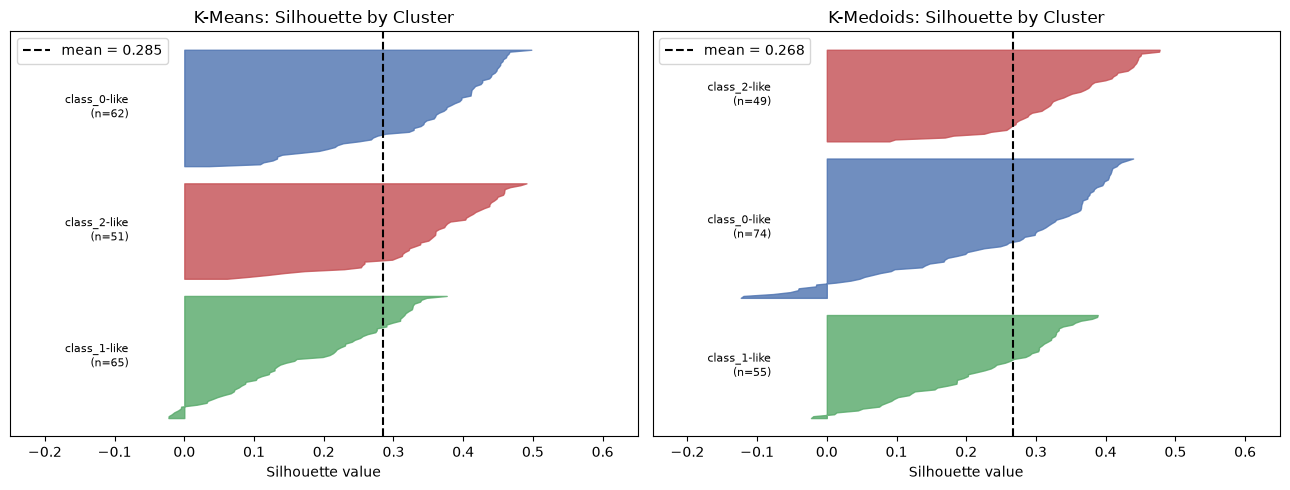

,K-Means,K-Medoids
cluster (matched class),,
class_0,0.343,0.254
class_1,0.177,0.221
class_2,0.351,0.341


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for ax, labels, colors, mapping, title in [(axes[0], km_labels, km_colors, km_map, 'K-Means'),
                                          (axes[1], kmed_labels, kmed_colors, kmed_map, 'K-Medoids')]:
    sample_sil = silhouette_samples(X, labels)
    y_lower = 0
    for c in range(3):
        vals = np.sort(sample_sil[labels == c])
        ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, color=palette[mapping[c]], alpha=0.8)
        ax.text(-0.08, y_lower + len(vals) / 2, f'{class_names[mapping[c]]}-like\n(n={len(vals)})', va='center', ha='right', fontsize=8)
        y_lower += len(vals) + 8
    ax.axvline(sample_sil.mean(), color='black', linestyle='--', label=f'mean = {sample_sil.mean():.3f}')
    ax.set_xlabel('Silhouette value')
    ax.set_yticks([])
    ax.set_xlim(-0.25, 0.65)
    ax.set_title(f'{title}: Silhouette by Cluster')
    ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({
    'K-Means': pd.Series(silhouette_samples(X, km_labels)).groupby([class_names[km_map[l]] for l in km_labels]).mean(),
    'K-Medoids': pd.Series(silhouette_samples(X, kmed_labels)).groupby([class_names[kmed_map[l]] for l in kmed_labels]).mean(),
}).round(3).rename_axis('cluster (matched class)')

**Observation:** The per-cluster view shows where each algorithm is weak. For K-Means, the class_0-like and class_2-like clusters are reasonably well separated (mean silhouette 0.343 and 0.351), while the class_1-like cluster is the weakest (0.177), because class_1 sits between the other two classes. For K-Medoids, the class_0-like cluster drops to 0.254 and has a visible tail of negative silhouette values. Those are the absorbed class_1 wines, which are closer to the class_1 cluster than to the cluster they were assigned to. Its class_1-like cluster scores slightly higher (0.221) only because its most ambiguous members were moved out of it.

### Supplementary checks

These checks test whether the results above hold up:

1. Is k = 3 actually the best number of clusters by silhouette?
2. Are the results stable across random starting points?
3. Does K-Medoids improve with Manhattan distance, which it supports and K-Means does not?

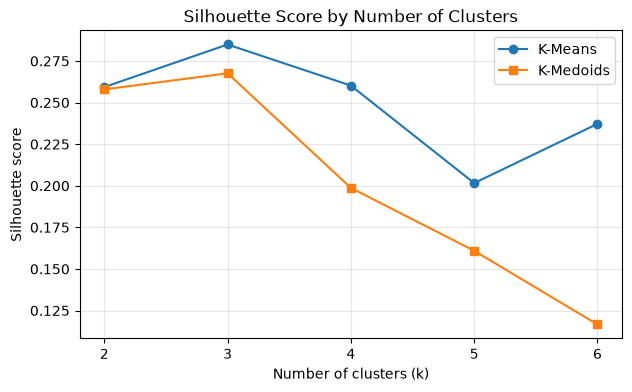

,k,K-Means silhouette,K-Medoids silhouette
0,2,0.2593,0.2579
1,3,0.2849,0.2676
2,4,0.2602,0.1987
3,5,0.2016,0.1609
4,6,0.2372,0.1166


In [17]:
k_rows = []
for k in range(2, 7):
    a = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    b = kmedoids.KMedoids(n_clusters=k, metric='euclidean', random_state=RANDOM_STATE).fit(X).labels_
    k_rows.append({'k': k, 'K-Means silhouette': silhouette_score(X, a), 'K-Medoids silhouette': silhouette_score(X, b)})
k_df = pd.DataFrame(k_rows).round(4)

plt.figure(figsize=(7, 4))
plt.plot(k_df['k'], k_df['K-Means silhouette'], marker='o', label='K-Means')
plt.plot(k_df['k'], k_df['K-Medoids silhouette'], marker='s', label='K-Medoids')
plt.xticks(k_df['k'])
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette Score by Number of Clusters')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
k_df

In [18]:
seeds = range(10)
stability = pd.DataFrame({
    'K-Means ARI': [adjusted_rand_score(y, KMeans(3, n_init=10, random_state=s).fit_predict(X)) for s in seeds],
    'K-Medoids ARI': [adjusted_rand_score(y, kmedoids.KMedoids(3, metric='euclidean', random_state=s).fit(X).labels_) for s in seeds],
}, index=pd.Index(seeds, name='random seed')).round(4)
print('distinct results across 10 seeds:', stability.nunique().to_dict())
stability.describe().loc[['mean', 'min', 'max']]

distinct results across 10 seeds: {'K-Means ARI': 2, 'K-Medoids ARI': 1}


,K-Means ARI,K-Medoids ARI
mean,0.89924,0.7411
min,0.89750,0.7411
max,0.91490,0.7411


In [19]:
kmed_l1 = kmedoids.KMedoids(n_clusters=3, metric='manhattan', random_state=RANDOM_STATE).fit(X)
pd.DataFrame({'silhouette score': [kmed_sil, silhouette_score(X, kmed_l1.labels_)],
              'adjusted rand index': [kmed_ari, adjusted_rand_score(y, kmed_l1.labels_)]},
             index=['K-Medoids (Euclidean)', 'K-Medoids (Manhattan)']).round(4)

,silhouette score,adjusted rand index
K-Medoids (Euclidean),0.2676,0.7411
K-Medoids (Manhattan),0.2716,0.7694


In [20]:
# how far is each k-means centroid from the closest real wine
centroid_gap = pairwise_distances(kmeans.cluster_centers_, X).min(axis=1)
typical_spacing = np.median(np.sort(pairwise_distances(X), axis=1)[:, 1])
print('distance from each centroid to its nearest actual wine:', centroid_gap.round(2))
print(f'median distance between a wine and its nearest neighbor: {typical_spacing:.2f}')

distance from each centroid to its nearest actual wine: [1.55 1.08 1.34]
median distance between a wine and its nearest neighbor: 1.74


**Observation:** 1. **k = 3 is the best choice for both algorithms.** It has the highest silhouette score for K-Means (0.2849) and for K-Medoids (0.2676), which supports using the number of cultivars as k. At k = 4 and above, K-Medoids degrades faster than K-Means (0.1166 vs. 0.2372 at k = 6).
2. **Both algorithms are stable.** K-Medoids produced the identical clustering (ARI 0.7411) for all 10 random seeds. K-Means produced two slightly different solutions across the seeds (ARI 0.8975 or 0.9149, mean 0.8992), so its result varies a little with the starting points, even with 10 restarts per run. The gap between the two algorithms is therefore not a matter of unlucky random seeds.
3. **Manhattan distance helps K-Medoids slightly.** With Manhattan distance, K-Medoids improves to a silhouette of 0.2716 and an ARI of 0.7694. It is still below K-Means, but the change shows that the distance metric is a real tuning choice that K-Medoids supports and standard K-Means does not.
4. **The K-Means centroids lie inside the data.** Each centroid is 1.08 to 1.55 units from its nearest real wine, which is closer than the typical spacing between neighboring wines (median 1.74). On this dataset, the centroids already sit in dense, realistic regions, so requiring a center to be a real wine gives K-Medoids little advantage and costs it some flexibility in positioning.

## Analysis

### Which algorithm produced better-defined clusters?

**K-Means produced better-defined clusters on both metrics.**

| | K-Means | K-Medoids |
|---|---|---|
| Silhouette score | **0.2849** | 0.2676 |
| Adjusted Rand Index | **0.8975** | 0.7411 |
| Wines in a cluster matched to another class | **6** | 16 |

The silhouette difference is small (0.017), meaning both algorithms found similarly compact clusters in a geometric sense. The ARI difference is large (0.156), meaning K-Means' clusters match the real cultivars much more closely. Both silhouette scores are modest, around 0.27 to 0.28, which reflects real overlap between the cultivars in 13 dimensions rather than a failure of either algorithm.

### What differences appear in cluster shapes or positioning?

* **Center positions.** K-Means centroids are averages, so they sit in the middle of each group. K-Medoids must pick a real wine as each center. Its class_0 medoid (wine 35) lies on the side of the class_0 group facing class_1, which moves that cluster's boundary toward class_1.
* **Cluster sizes and boundaries.** Because of that shift, the K-Medoids class_0 cluster grew to 74 wines (versus 62 for K-Means) by taking in a band of 15 class_1 wines. K-Means kept class_1 mostly together (65 of 71 wines).
* **Shared structure.** Both algorithms agree on the overall layout: three groups arranged in an arc, with class_2 and class_0 at the ends, clearly separated, and class_1 in the middle. Every disagreement between the algorithms involves class_1 wines near the class_0 border.
* **Objective.** K-Means minimizes squared distances, which penalizes far-away points heavily and pulls its centers toward the middle of each group. K-Medoids minimizes plain distances, so it puts less weight on distant points and settles on a center that is good for the bulk of its cluster even if the boundary sits farther over.

### When K-Means or K-Medoids may be preferable

**K-Means is preferable when:**
* The features are numeric and standardized, and averaging them makes sense, as with these chemical measurements.
* Clusters are roughly round and similar in size. The Wine data fits this well, which is why K-Means scored higher here.
* The dataset is large. Each K-Means iteration is fast, while K-Medoids must compare points with one another and becomes slow on very large datasets.

**K-Medoids is preferable when:**
* The data contains outliers or noise. Because it minimizes plain distances and its centers must be real points, a few extreme values cannot drag a cluster center into empty space.
* A non-Euclidean distance is needed, such as Manhattan distance, or a custom dissimilarity for categorical, text, or mixed data where an "average" point does not exist. K-Medoids accepts any distance measure; K-Means is tied to the mean.
* An interpretable representative is needed. A medoid is a real example that can be inspected, such as "wine 35 is the typical class_0 wine." A K-Means centroid is a blend of measurements that no actual wine has.
* Reproducibility matters. In this lab, K-Medoids returned the identical clustering for every random seed, while K-Means varied slightly.

**For this dataset,** K-Means is the better choice. The data is clean, numeric, and standardized, its centroids already fall in realistic regions, and it recovered the cultivars with an ARI of 0.8975, compared with 0.7411 for K-Medoids.